# Solving the n-Queens Problem using Local Search

Student Name: Lâm Tú Nhi

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [56]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your working directory is now Google Drive: My Drive > Colab Notebooks


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


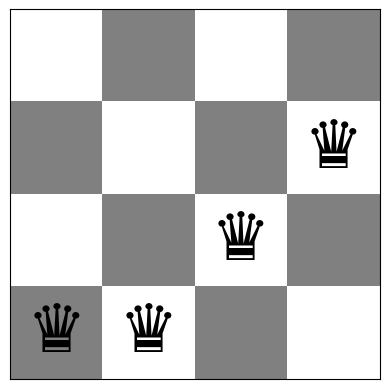

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [58]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


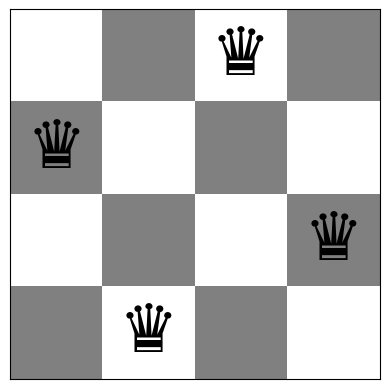

In [59]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

Initial: [3 3 2 1] conflicts: 4
Final: [np.int64(3), 0, np.int64(2), np.int64(1)] conflicts: 1
Improving steps: 1 conflicts() evaluations: 25
Board with 1 conflicts.


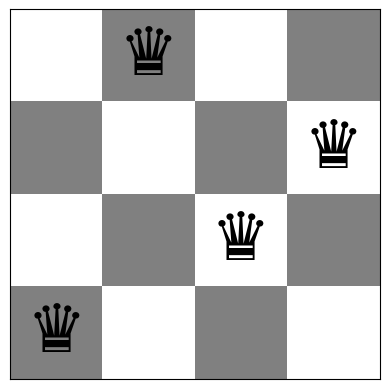

In [60]:
# Task 1 — Steepest-ascent Hill Climbing
def all_neighbors(board):
    """Sinh tất cả trạng thái bằng cách đổi hàng của một quân hậu."""
    board = list(board)
    n = len(board)
    for col in range(n):
        for row in range(n):
            if row != board[col]:
                neighbor = board.copy()
                neighbor[col] = row
                yield neighbor

def steepest_hill_climbing(initial_board, max_steps=10000):
    board = list(initial_board)
    history = [conflicts(board)]
    evaluations = 1
    for _ in range(max_steps):
        current = history[-1]
        best_board, best_score = board, current
        for neighbor in all_neighbors(board):
            score = conflicts(neighbor)
            evaluations += 1
            if score < best_score:
                best_board, best_score = neighbor, score
        if best_score >= current:
            break
        board = best_board
        history.append(best_score)
        if best_score == 0:
            break
    return board, history, evaluations

np.random.seed(1234)
demo = random_board(4)
solution, history, evaluations = steepest_hill_climbing(demo)
print("Initial:", demo, "conflicts:", conflicts(demo))
print("Final:", solution, "conflicts:", conflicts(solution))
print("Improving steps:", len(history)-1, "conflicts() evaluations:", evaluations)
show_board(solution)

### Minh họa từng bước Task 1 (bàn cờ 4-Queens)

Ô dưới đây dùng trạng thái đầu cố định `[2, 3, 0, 2]` để in ra toàn bộ láng giềng ở mỗi vòng, số xung đột của từng trạng thái, nước đi tốt nhất được chọn và đường đi cuối cùng.

TASK 1: STEEPEST-ASCENT HILL CLIMBING
Trang thai ban dau: [2, 3, 0, 2] | f = 3

VONG 1 - Danh gia tat ca lang gieng
  Cot 1, chuyen hau sang hang 1: [0, 3, 0, 2] | f = 1
  Cot 1, chuyen hau sang hang 2: [1, 3, 0, 2] | f = 0
  Cot 1, chuyen hau sang hang 4: [3, 3, 0, 2] | f = 1
  Cot 2, chuyen hau sang hang 1: [2, 0, 0, 2] | f = 4
  Cot 2, chuyen hau sang hang 2: [2, 1, 0, 2] | f = 4
  Cot 2, chuyen hau sang hang 3: [2, 2, 0, 2] | f = 4
  Cot 3, chuyen hau sang hang 2: [2, 3, 1, 2] | f = 3
  Cot 3, chuyen hau sang hang 3: [2, 3, 2, 2] | f = 5
  Cot 3, chuyen hau sang hang 4: [2, 3, 3, 2] | f = 4
  Cot 4, chuyen hau sang hang 1: [2, 3, 0, 0] | f = 3
  Cot 4, chuyen hau sang hang 2: [2, 3, 0, 1] | f = 4
  Cot 4, chuyen hau sang hang 4: [2, 3, 0, 3] | f = 3
Chon trang thai tot nhat: [1, 3, 0, 2] | f = 0
Da tim thay loi giai.

DUONG DI DUOC CHAP NHAN:
Trang thai 0: [2, 3, 0, 2] | f = 3
Trang thai 1: [1, 3, 0, 2] | f = 0
So buoc chap nhan: 1
So lan goi conflicts() trong demo: 13
Board with 0

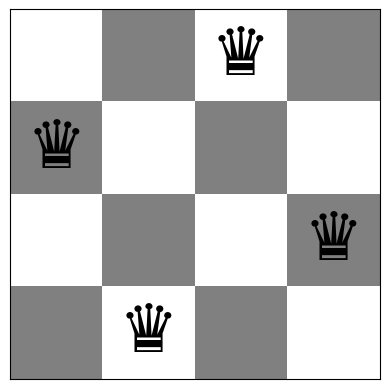

([1, 3, 0, 2], [3, 0], 13, [[2, 3, 0, 2], [1, 3, 0, 2]])

In [61]:
def demo_steepest_step_by_step(initial_board):
    board = list(initial_board)
    history = [conflicts(board)]
    path = [board.copy()]
    calls = 1
    n = len(board)
    print("=" * 65)
    print("TASK 1: STEEPEST-ASCENT HILL CLIMBING")
    print("Trang thai ban dau:", board, "| f =", history[-1])

    round_no = 0
    while history[-1] > 0:
        round_no += 1
        current_score = history[-1]
        best_board = board
        best_score = current_score
        print(f"\nVONG {round_no} - Danh gia tat ca lang gieng")
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue
                neighbor = board.copy()
                neighbor[col] = row
                score = conflicts(neighbor)
                calls += 1
                print(f"  Cot {col+1}, chuyen hau sang hang {row+1}: "
                      f"{neighbor} | f = {score}")
                if score < best_score:
                    best_board, best_score = neighbor, score
        if best_score >= current_score:
            print("Khong con nuoc di cai thien. Dung tai cuc tieu cuc bo.")
            break
        board = best_board.copy()
        history.append(best_score)
        path.append(board.copy())
        print("Chon trang thai tot nhat:", board, "| f =", best_score)
        if best_score == 0:
            print("Da tim thay loi giai.")
            break

    print("\nDUONG DI DUOC CHAP NHAN:")
    for i, state in enumerate(path):
        print(f"Trang thai {i}: {state} | f = {history[i]}")
    print("So buoc chap nhan:", len(history)-1)
    print("So lan goi conflicts() trong demo:", calls)
    show_board(board)
    return board, history, calls, path

demo_steepest_step_by_step([2, 3, 0, 2])

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

Initial: [3 3 2 1] conflicts: 4
Final: [1, np.int64(3), np.int64(2), 0] conflicts: 1
Improving steps: 2 conflicts() evaluations: 37
Board with 1 conflicts.


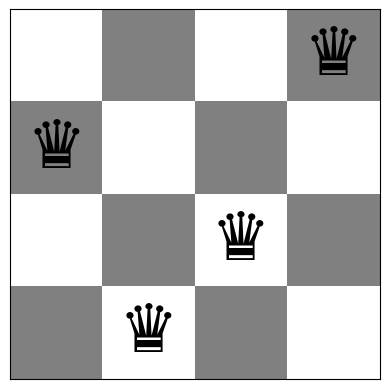

In [62]:
# Task 2 — Inefficient Stochastic Hill Climbing
# Enumerate every neighbor that improves the score, then choose one at random.
def inefficient_stochastic_hill_climbing(initial_board, max_steps=10000):
    board = list(initial_board)
    history = [conflicts(board)]
    evaluations = 1
    for _ in range(max_steps):
        current = history[-1]
        improving = []
        for neighbor in all_neighbors(board):
            score = conflicts(neighbor)
            evaluations += 1
            if score < current:
                improving.append((neighbor, score))
        if not improving:
            break
        board, score = improving[np.random.randint(len(improving))]
        history.append(score)
        if score == 0:
            break
    return board, history, evaluations

np.random.seed(1234)
demo = random_board(4)
solution, history, evaluations = inefficient_stochastic_hill_climbing(demo)
print("Initial:", demo, "conflicts:", conflicts(demo))
print("Final:", solution, "conflicts:", conflicts(solution))
print("Improving steps:", len(history)-1, "conflicts() evaluations:", evaluations)
show_board(solution)

### Minh họa từng bước Task 2 (Inefficient Stochastic Hill Climbing)

Hàm minh họa in toàn bộ láng giềng ở mỗi vòng, danh sách nước đi cải thiện và nước đi được chọn ngẫu nhiên. Seed được cố định để dễ tái lập chuỗi lựa chọn trong cùng môi trường.

TASK 2: INEFFICIENT STOCHASTIC HILL CLIMBING
Trang thai ban dau: [2, 3, 0, 2] | f = 3

VONG 1 - Danh gia tat ca lang gieng
  Cot 1, chuyen hau sang hang 1: [0, 3, 0, 2] | f = 1
  Cot 1, chuyen hau sang hang 2: [1, 3, 0, 2] | f = 0
  Cot 1, chuyen hau sang hang 4: [3, 3, 0, 2] | f = 1
  Cot 2, chuyen hau sang hang 1: [2, 0, 0, 2] | f = 4
  Cot 2, chuyen hau sang hang 2: [2, 1, 0, 2] | f = 4
  Cot 2, chuyen hau sang hang 3: [2, 2, 0, 2] | f = 4
  Cot 3, chuyen hau sang hang 2: [2, 3, 1, 2] | f = 3
  Cot 3, chuyen hau sang hang 3: [2, 3, 2, 2] | f = 5
  Cot 3, chuyen hau sang hang 4: [2, 3, 3, 2] | f = 4
  Cot 4, chuyen hau sang hang 1: [2, 3, 0, 0] | f = 3
  Cot 4, chuyen hau sang hang 2: [2, 3, 0, 1] | f = 4
  Cot 4, chuyen hau sang hang 4: [2, 3, 0, 3] | f = 3
So nuoc di cai thien: 3
Chon ngau nhien: cot 1 sang hang 4
Trang thai moi: [3, 3, 0, 2] | f = 1

VONG 2 - Danh gia tat ca lang gieng
  Cot 1, chuyen hau sang hang 1: [0, 3, 0, 2] | f = 1
  Cot 1, chuyen hau sang hang 2: [1, 3, 0,

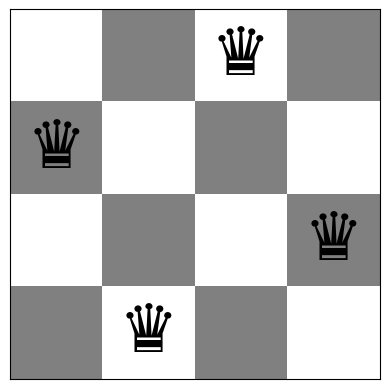

([1, 3, 0, 2], [3, 1, 0], 25, [[2, 3, 0, 2], [3, 3, 0, 2], [1, 3, 0, 2]])

In [63]:
def demo_inefficient_stochastic_step_by_step(initial_board, seed=42):
    np.random.seed(seed)
    board = list(initial_board)
    history = [conflicts(board)]
    path = [board.copy()]
    calls = 1
    n = len(board)
    print("=" * 65)
    print("TASK 2: INEFFICIENT STOCHASTIC HILL CLIMBING")
    print("Trang thai ban dau:", board, "| f =", history[-1])

    round_no = 0
    while history[-1] > 0:
        round_no += 1
        current_score = history[-1]
        improving = []
        print(f"\nVONG {round_no} - Danh gia tat ca lang gieng")
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue
                neighbor = board.copy()
                neighbor[col] = row
                score = conflicts(neighbor)
                calls += 1
                print(f"  Cot {col+1}, chuyen hau sang hang {row+1}: "
                      f"{neighbor} | f = {score}")
                if score < current_score:
                    improving.append((neighbor, score, col, row))
        print("So nuoc di cai thien:", len(improving))
        if not improving:
            print("Khong con nuoc di cai thien. Thuat toan dung.")
            break
        idx = np.random.randint(len(improving))
        board, score, col, row = improving[idx]
        board = board.copy()
        history.append(score)
        path.append(board.copy())
        print(f"Chon ngau nhien: cot {col+1} sang hang {row+1}")
        print("Trang thai moi:", board, "| f =", score)
        if score == 0:
            print("Da tim thay loi giai.")
            break

    print("\nDUONG DI DUOC CHAP NHAN:")
    for i, state in enumerate(path):
        print(f"Trang thai {i}: {state} | f = {history[i]}")
    print("So buoc chap nhan:", len(history)-1)
    print("So lan goi conflicts() trong demo:", calls)
    show_board(board)
    return board, history, calls, path

demo_inefficient_stochastic_step_by_step([2, 3, 0, 2], seed=42)

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

Initial: [7 3 6 5 4 4 0 1] conflicts: 9
Final: [1, np.int64(3), 5, 7, np.int64(4), 6, np.int64(0), 2] conflicts: 1
Improving steps: 6 conflicts() evaluations: 219
Board with 1 conflicts.


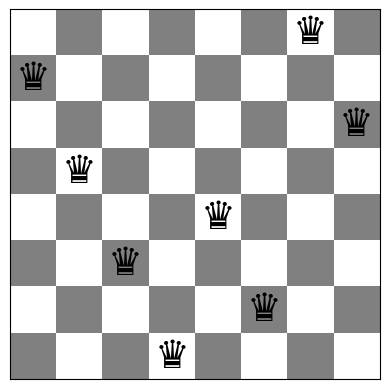

In [64]:
# Task 3 — Efficient Stochastic / First-choice Hill Climbing
def random_neighbor(board):
    b = list(board)
    n = len(b)
    col = np.random.randint(n)
    row = np.random.randint(n-1)
    if row >= b[col]:
        row += 1
    b[col] = row
    return b

def efficient_stochastic_hill_climbing(initial_board, max_steps=10000, max_failed_trials=None):
    board = list(initial_board)
    n = len(board)
    if max_failed_trials is None:
        max_failed_trials = max(20, 3*n*(n-1))
    history = [conflicts(board)]
    evaluations = 1
    failures = 0
    for _ in range(max_steps):
        if history[-1] == 0:
            break
        neighbor = random_neighbor(board)
        score = conflicts(neighbor)
        evaluations += 1
        if score < history[-1]:
            board = neighbor
            history.append(score)
            failures = 0
        else:
            failures += 1
        if failures >= max_failed_trials:
            break
    return board, history, evaluations

np.random.seed(1234)
demo = random_board(8)
solution, history, evaluations = efficient_stochastic_hill_climbing(demo)
print("Initial:", demo, "conflicts:", conflicts(demo))
print("Final:", solution, "conflicts:", conflicts(solution))
print("Improving steps:", len(history)-1, "conflicts() evaluations:", evaluations)
show_board(solution, fontsize=28)

### Minh họa từng bước Task 3 (Efficient Stochastic / First-choice Hill Climbing)

Khác Task 2, mỗi lần thử ở đây chỉ sinh và đánh giá một láng giềng ngẫu nhiên. Log sẽ ghi rõ nước đi được chấp nhận hay từ chối. Để tránh output quá dài, ví dụ dùng bàn cờ 4-Queens và giới hạn số lần thất bại liên tiếp.

TASK 3: EFFICIENT STOCHASTIC HILL CLIMBING
Trang thai ban dau: [2, 3, 0, 2] | f = 3
Gioi han that bai lien tiep: 30

Lan thu 1: lang gieng [2, 3, 1, 2] | f = 3
TU CHOI: khong cai thien.
So lan that bai lien tiep: 1

Lan thu 2: lang gieng [2, 3, 3, 2] | f = 4
TU CHOI: khong cai thien.
So lan that bai lien tiep: 2

Lan thu 3: lang gieng [2, 3, 0, 0] | f = 3
TU CHOI: khong cai thien.
So lan that bai lien tiep: 3

Lan thu 4: lang gieng [3, 3, 0, 2] | f = 1
CHAP NHAN: xung dot giam tu 3 xuong 1
Trang thai hien tai: [3, 3, 0, 2]

Lan thu 5: lang gieng [3, 2, 0, 2] | f = 2
TU CHOI: khong cai thien.
So lan that bai lien tiep: 1

Lan thu 6: lang gieng [3, 3, 3, 2] | f = 4
TU CHOI: khong cai thien.
So lan that bai lien tiep: 2

Lan thu 7: lang gieng [3, 3, 1, 2] | f = 3
TU CHOI: khong cai thien.
So lan that bai lien tiep: 3

Lan thu 8: lang gieng [3, 3, 0, 3] | f = 3
TU CHOI: khong cai thien.
So lan that bai lien tiep: 4

Lan thu 9: lang gieng [3, 0, 0, 2] | f = 2
TU CHOI: khong cai thien.
So la

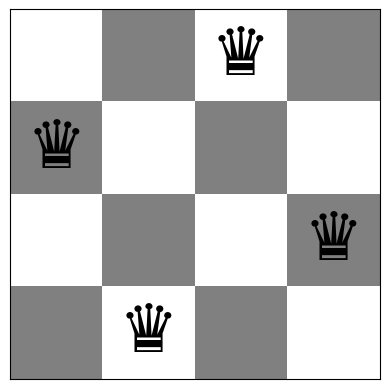

([1, 3, 0, 2], [3, 1, 0], 14, [[2, 3, 0, 2], [3, 3, 0, 2], [1, 3, 0, 2]])

In [65]:
def demo_efficient_stochastic_step_by_step(
    initial_board, seed=42, max_failed_trials=30, max_steps=1000
):
    np.random.seed(seed)
    board = list(initial_board)
    history = [conflicts(board)]
    path = [board.copy()]
    calls = 1
    failures = 0
    attempts = 0
    n = len(board)

    print("=" * 65)
    print("TASK 3: EFFICIENT STOCHASTIC HILL CLIMBING")
    print("Trang thai ban dau:", board, "| f =", history[-1])
    print("Gioi han that bai lien tiep:", max_failed_trials)

    while history[-1] > 0 and failures < max_failed_trials and attempts < max_steps:
        attempts += 1
        neighbor = random_neighbor(board)
        score = conflicts(neighbor)
        calls += 1
        print(f"\nLan thu {attempts}: lang gieng {neighbor} | f = {score}")
        if score < history[-1]:
            old_score = history[-1]
            board = neighbor.copy()
            history.append(score)
            path.append(board.copy())
            failures = 0
            print(f"CHAP NHAN: xung dot giam tu {old_score} xuong {score}")
            print("Trang thai hien tai:", board)
        else:
            failures += 1
            print("TU CHOI: khong cai thien.")
            print("So lan that bai lien tiep:", failures)

    if history[-1] == 0:
        print("\nDa tim thay loi giai.")
    else:
        print("\nDung do dat gioi han thu that bai/so buoc.")

    print("\nDUONG DI DUOC CHAP NHAN:")
    for i, state in enumerate(path):
        print(f"Trang thai {i}: {state} | f = {history[i]}")
    print("So buoc chap nhan:", len(history)-1)
    print("So lan goi conflicts() trong demo:", calls)
    show_board(board)
    return board, history, calls, path

demo_efficient_stochastic_step_by_step([2, 3, 0, 2], seed=42)

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [66]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def random_restart(algorithm, n, max_restarts=100, verbose=True):
    best_board = None
    best_conflicts = float("inf")

    total_steps = 0
    total_evaluations = 0
    total_runtime = 0.0
    restarts_used = 0
    success = False

    # Luu thong tin tung lan khoi dong
    restart_history = []

    for restart in range(1, max_restarts + 1):
        initial_board = random_board(n)
        initial_conflicts = conflicts(initial_board)

        start_time = time.perf_counter()
        board, history, evaluations = algorithm(initial_board)
        elapsed = time.perf_counter() - start_time

        final_conflicts = conflicts(board)
        steps = len(history) - 1

        total_steps += steps
        total_evaluations += evaluations
        total_runtime += elapsed
        restarts_used = restart

        restart_history.append({
            "restart": restart,
            "initial_conflicts": initial_conflicts,
            "final_conflicts": final_conflicts,
            "steps": steps,
            "evaluations": evaluations,
            "runtime_seconds": elapsed
        })

        if verbose:
            print(
                f"Restart {restart:3d}: "
                f"initial conflicts = {initial_conflicts:2d}, "
                f"final conflicts = {final_conflicts:2d}"
            )

        if final_conflicts < best_conflicts:
            best_conflicts = final_conflicts
            best_board = list(board)

        # Dung som khi tim duoc loi giai
        if final_conflicts == 0:
            success = True
            if verbose:
                print("Da tim thay loi giai khong xung dot!")
            break

    return {
        "algorithm": algorithm.__name__,
        "n": n,
        "board": best_board,
        "final_conflicts": best_conflicts,
        "success": success,
        "restarts": restarts_used,
        "total_steps": total_steps,
        "evaluations": total_evaluations,
        "runtime_seconds": total_runtime,
        "restart_history": restart_history
    }



THUAT TOAN: steepest_hill_climbing
Restart   1: initial conflicts =  9, final conflicts =  2
Restart   2: initial conflicts =  5, final conflicts =  1
Restart   3: initial conflicts =  9, final conflicts =  1
Restart   4: initial conflicts =  5, final conflicts =  2
Restart   5: initial conflicts =  8, final conflicts =  0
Da tim thay loi giai khong xung dot!

KET QUA TOT NHAT
Ban co: [np.int64(0), 4, 7, np.int64(5), np.int64(2), np.int64(6), 1, np.int64(3)]
So xung dot tot nhat: 0
Tim thay loi giai: True
So lan khoi dong: 5
Tong buoc cai thien: 15
Tong so lan danh gia: 1069
Thoi gian: 0.015672 giay
Board with 0 conflicts.


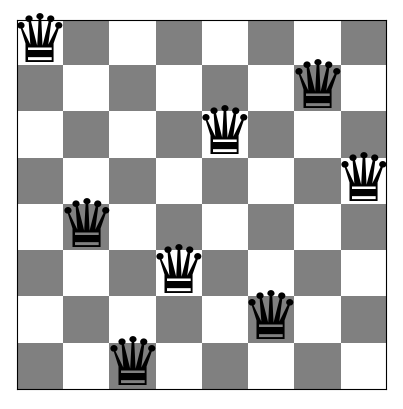


THUAT TOAN: inefficient_stochastic_hill_climbing
Restart   1: initial conflicts =  7, final conflicts =  0
Da tim thay loi giai khong xung dot!

KET QUA TOT NHAT
Ban co: [5, np.int64(2), 0, np.int64(7), 4, 1, np.int64(3), np.int64(6)]
So xung dot tot nhat: 0
Tim thay loi giai: True
So lan khoi dong: 1
Tong buoc cai thien: 5
Tong so lan danh gia: 281
Thoi gian: 0.002737 giay
Board with 0 conflicts.


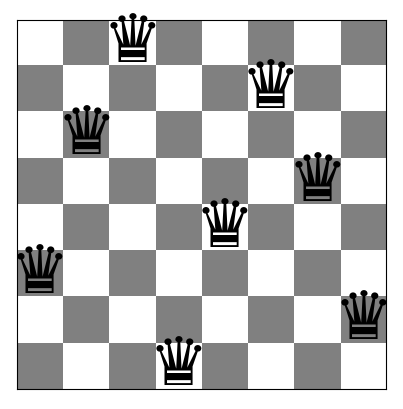


THUAT TOAN: efficient_stochastic_hill_climbing
Restart   1: initial conflicts =  6, final conflicts =  3
Restart   2: initial conflicts =  8, final conflicts =  2
Restart   3: initial conflicts =  7, final conflicts =  2
Restart   4: initial conflicts = 10, final conflicts =  2
Restart   5: initial conflicts =  5, final conflicts =  2
Restart   6: initial conflicts = 11, final conflicts =  2
Restart   7: initial conflicts =  6, final conflicts =  2
Restart   8: initial conflicts =  8, final conflicts =  2
Restart   9: initial conflicts =  8, final conflicts =  1
Restart  10: initial conflicts =  9, final conflicts =  1
Restart  11: initial conflicts =  6, final conflicts =  2
Restart  12: initial conflicts =  9, final conflicts =  2
Restart  13: initial conflicts =  6, final conflicts =  2
Restart  14: initial conflicts =  7, final conflicts =  1
Restart  15: initial conflicts = 11, final conflicts =  0
Da tim thay loi giai khong xung dot!

KET QUA TOT NHAT
Ban co: [5, 7, np.int64(1),

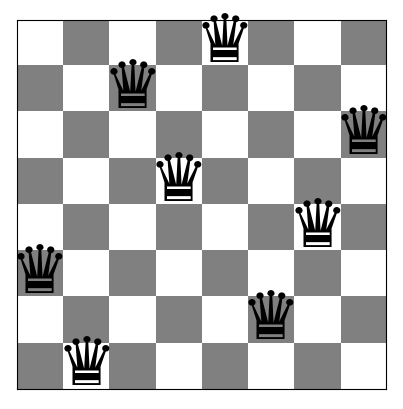

In [67]:

algorithms = [
    steepest_hill_climbing,
    inefficient_stochastic_hill_climbing,
    efficient_stochastic_hill_climbing
]

n = 8
max_restarts = 100
results = []

for i, algorithm in enumerate(algorithms):
    print("\n" + "=" * 65)
    print("THUAT TOAN:", algorithm.__name__)

    np.random.seed(1234 + i)

    result = random_restart(
        algorithm,
        n=n,
        max_restarts=max_restarts,
        verbose=True
    )

    results.append(result)

    print("\nKET QUA TOT NHAT")
    print("Ban co:", result["board"])
    print("So xung dot tot nhat:", result["final_conflicts"])
    print("Tim thay loi giai:", result["success"])
    print("So lan khoi dong:", result["restarts"])
    print("Tong buoc cai thien:", result["total_steps"])
    print("Tong so lan danh gia:", result["evaluations"])
    print(f"Thoi gian: {result['runtime_seconds']:.6f} giay")

    show_board(result["board"])


In [68]:

summary = []

for result in results:
    summary.append({
        "N": result["n"],
        "Algorithm": result["algorithm"],
        "Best conflicts": result["final_conflicts"],
        "Solution found": result["success"],
        "Restarts used": result["restarts"],
        "Total steps": result["total_steps"],
        "Evaluations": result["evaluations"],
        "Runtime (seconds)": result["runtime_seconds"]
    })

results_df = pd.DataFrame(summary)

display(
    results_df.style.format({
        "Runtime (seconds)": "{:.6f}"
    })
)


,N,Algorithm,Best conflicts,Solution found,Restarts used,Total steps,Evaluations,Runtime (seconds)
0,8,steepest_hill_climbing,0,True,5,15,1069,0.015672
1,8,inefficient_stochastic_hill_climbing,0,True,1,5,281,0.002737
2,8,efficient_stochastic_hill_climbing,0,True,15,68,2986,0.044840


In [69]:

N_VALUES = [4, 8]
N_RUNS = 20
MAX_RESTARTS = 100
BASE_SEED = 2026

experiment_records = []

for board_size in N_VALUES:
    for alg_index, algorithm in enumerate(algorithms):
        for run in range(N_RUNS):
            seed = (
                BASE_SEED
                + board_size * 10000
                + alg_index * 1000
                + run
            )
            np.random.seed(seed)

            result = random_restart(
                algorithm,
                n=board_size,
                max_restarts=MAX_RESTARTS,
                verbose=False
            )

            experiment_records.append({
                "N": board_size,
                "Algorithm": algorithm.__name__,
                "Run": run + 1,
                "Success": result["success"],
                "Best conflicts": result["final_conflicts"],
                "Restarts": result["restarts"],
                "Steps": result["total_steps"],
                "Evaluations": result["evaluations"],
                "Runtime (seconds)": result["runtime_seconds"]
            })

experiment_df = pd.DataFrame(experiment_records)

print("CHI TIET CAC LAN CHAY")
display(experiment_df.head(10))

experiment_summary = (
    experiment_df
    .groupby(["N", "Algorithm"], as_index=False)
    .agg(
        Runs=("Run", "count"),
        Successes=("Success", "sum"),
        Mean_best_conflicts=("Best conflicts", "mean"),
        Mean_restarts=("Restarts", "mean"),
        Mean_steps=("Steps", "mean"),
        Mean_evaluations=("Evaluations", "mean"),
        Mean_runtime=("Runtime (seconds)", "mean")
    )
)

experiment_summary["Success rate (%)"] = (
    experiment_summary["Successes"]
    / experiment_summary["Runs"] * 100
)

print("TONG HOP THI NGHIEM LAP LAI")
display(
    experiment_summary.style.format({
        "Mean_best_conflicts": "{:.3f}",
        "Mean_restarts": "{:.2f}",
        "Mean_steps": "{:.2f}",
        "Mean_evaluations": "{:.2f}",
        "Mean_runtime": "{:.6f}",
        "Success rate (%)": "{:.1f}"
    })
)


CHI TIET CAC LAN CHAY


,N,Algorithm,Run,Success,Best conflicts,Restarts,Steps,Evaluations,Runtime (seconds)
0,4,steepest_hill_climbing,1,True,0,3,4,75,0.001018
1,4,steepest_hill_climbing,2,True,0,1,2,25,0.000212
2,4,steepest_hill_climbing,3,True,0,2,3,50,0.000273
3,4,steepest_hill_climbing,4,True,0,3,4,75,0.000573
4,4,steepest_hill_climbing,5,True,0,4,5,100,0.000588
5,4,steepest_hill_climbing,6,True,0,2,3,50,0.000268
6,4,steepest_hill_climbing,7,True,0,1,2,25,0.000140
7,4,steepest_hill_climbing,8,True,0,3,4,75,0.000458
8,4,steepest_hill_climbing,9,True,0,2,3,50,0.000268
9,4,steepest_hill_climbing,10,True,0,1,2,25,0.000138


TONG HOP THI NGHIEM LAP LAI


,N,Algorithm,Runs,Successes,Mean_best_conflicts,Mean_restarts,Mean_steps,Mean_evaluations,Mean_runtime,Success rate (%)
0,4,efficient_stochastic_hill_climbing,20,20,0.000,1.90,4.10,57.30,0.000645,100.0
1,4,inefficient_stochastic_hill_climbing,20,20,0.000,3.30,5.15,93.30,0.000543,100.0
2,4,steepest_hill_climbing,20,20,0.000,2.35,3.75,63.55,0.000399,100.0
3,8,efficient_stochastic_hill_climbing,20,20,0.000,6.40,30.65,1298.95,0.019258,100.0
4,8,inefficient_stochastic_hill_climbing,20,20,0.000,6.05,30.50,1996.85,0.018407,100.0
5,8,steepest_hill_climbing,20,20,0.000,5.65,18.05,1276.85,0.012718,100.0


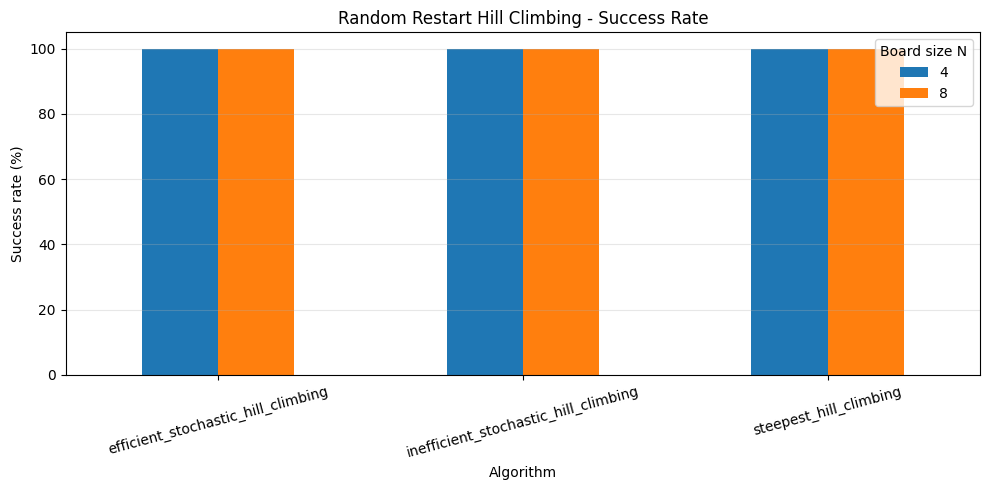

In [70]:

plot_data = experiment_summary.pivot(
    index="Algorithm",
    columns="N",
    values="Success rate (%)"
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 105),
    rot=15
)

ax.set_title("Random Restart Hill Climbing - Success Rate")
ax.set_xlabel("Algorithm")
ax.set_ylabel("Success rate (%)")
ax.legend(title="Board size N")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [71]:

import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def simulated_annealing(
    initial_board,
    initial_temp=10.0,
    cooling_rate=0.995,
    min_temp=1e-3,
    max_steps=10000
):
    """
    Simulated Annealing cho bai toan N-Queens.

    Tra ve:
        board: ban co tot nhat tim duoc
        history: so xung dot tot nhat qua tung buoc
        evaluations: so lan danh gia trang thai moi
    """
    if initial_temp <= 0:
        raise ValueError("initial_temp phai lon hon 0.")
    if not 0 < cooling_rate < 1:
        raise ValueError("cooling_rate phai nam trong khoang (0, 1).")
    if min_temp <= 0:
        raise ValueError("min_temp phai lon hon 0.")
    if max_steps < 1:
        raise ValueError("max_steps phai >= 1.")

    current_board = list(initial_board)
    current_score = conflicts(current_board)

    best_board = current_board.copy()
    best_score = current_score

    history = [best_score]
    evaluations = 1
    temperature = float(initial_temp)

    for step in range(max_steps):
        # Dung neu da tim thay loi giai
        if best_score == 0:
            break

        # Dung neu nhiet do da qua thap
        if temperature < min_temp:
            break

        # Tao mot trang thai lang gieng ngau nhien
        neighbor = random_neighbor(current_board)
        neighbor_score = conflicts(neighbor)
        evaluations += 1

        delta = neighbor_score - current_score

        # Chap nhan trang thai tot hon hoac bang
        if delta <= 0:
            accept = True
        else:
            # Chap nhan trang thai xau hon theo xac suat exp(-delta/T)
            probability = math.exp(-delta / temperature)
            accept = np.random.random() < probability

        if accept:
            current_board = list(neighbor)
            current_score = neighbor_score

        # Cap nhat trang thai tot nhat tung tim thay
        if current_score < best_score:
            best_score = current_score
            best_board = current_board.copy()

        history.append(best_score)

        # Lam nguoi
        temperature *= cooling_rate

    return best_board, history, evaluations



SIMULATED ANNEALING - N=4
Ban co ban dau: [1 3 0 3]
Xung dot ban dau: 1
Ban co tot nhat: [np.int64(1), np.int64(3), np.int64(0), 2]
Xung dot tot nhat: 0
Tim thay loi giai: True
So buoc: 2
So lan danh gia: 3
Thoi gian: 0.000092 giay
Board with 0 conflicts.


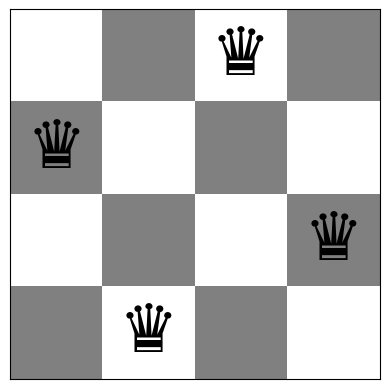

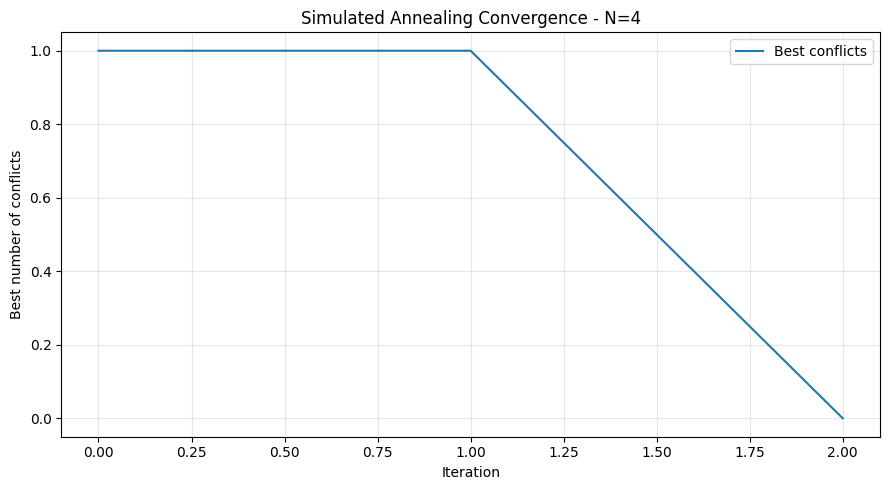


SIMULATED ANNEALING - N=8
Ban co ban dau: [5 5 7 5 6 3 3 5]
Xung dot ban dau: 12
Ban co tot nhat: [3, 1, 6, 4, 0, 7, 5, 2]
Xung dot tot nhat: 0
Tim thay loi giai: True
So buoc: 1111
So lan danh gia: 1112
Thoi gian: 0.016387 giay
Board with 0 conflicts.


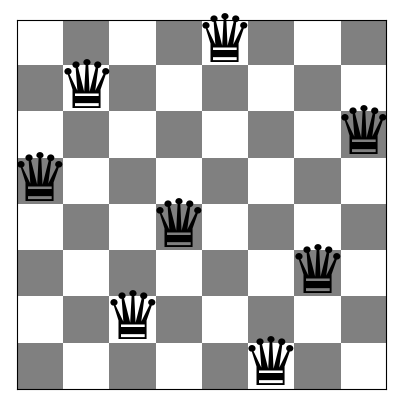

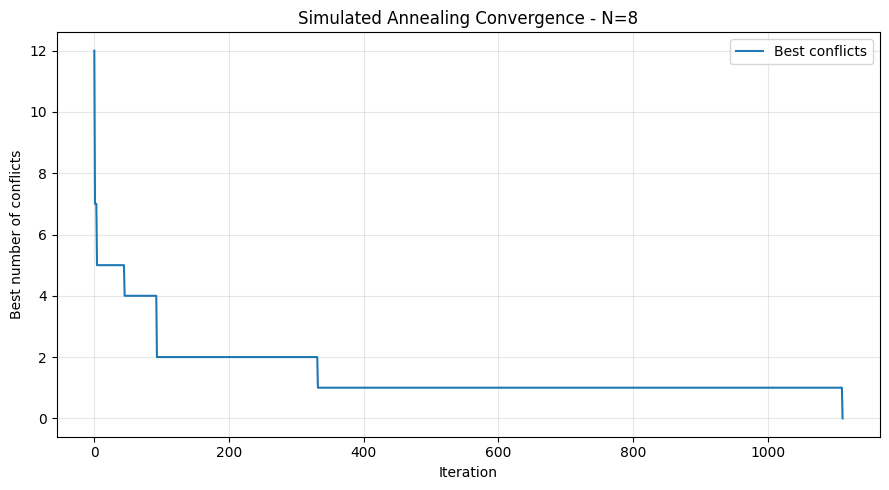

In [72]:

# Chay minh hoa SA tren ca N=4 va N=8
N_VALUES = [4, 8]
demo_results = {}

for n in N_VALUES:
    np.random.seed(2026 + n)

    initial_board = random_board(n)
    initial_conflicts = conflicts(initial_board)

    start_time = time.perf_counter()

    sa_board, sa_history, sa_evaluations = simulated_annealing(
        initial_board,
        initial_temp=10.0,
        cooling_rate=0.995,
        min_temp=1e-3,
        max_steps=10000
    )

    sa_runtime = time.perf_counter() - start_time
    best_conflicts = conflicts(sa_board)

    demo_results[n] = {
        "initial_board": initial_board,
        "initial_conflicts": initial_conflicts,
        "board": sa_board,
        "history": sa_history,
        "evaluations": sa_evaluations,
        "runtime": sa_runtime,
        "success": best_conflicts == 0
    }

    print("\n" + "=" * 50)
    print(f"SIMULATED ANNEALING - N={n}")
    print("Ban co ban dau:", initial_board)
    print("Xung dot ban dau:", initial_conflicts)
    print("Ban co tot nhat:", sa_board)
    print("Xung dot tot nhat:", best_conflicts)
    print("Tim thay loi giai:", best_conflicts == 0)
    print("So buoc:", len(sa_history) - 1)
    print("So lan danh gia:", sa_evaluations)
    print(f"Thoi gian: {sa_runtime:.6f} giay")

    show_board(sa_board)

    # Ve do thi hoi tu rieng cho tung kich thuoc
    plt.figure(figsize=(9, 5))
    plt.plot(sa_history, label="Best conflicts")
    plt.xlabel("Iteration")
    plt.ylabel("Best number of conflicts")
    plt.title(f"Simulated Annealing Convergence - N={n}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


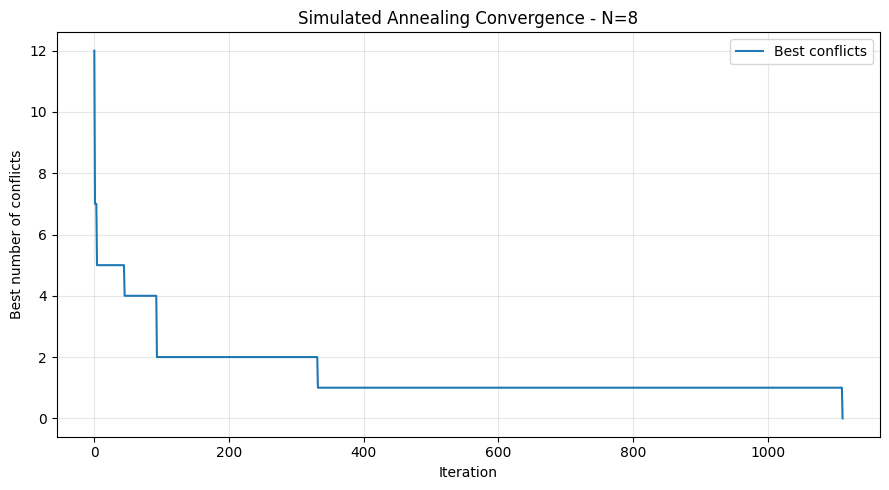

In [73]:

plt.figure(figsize=(9, 5))

plt.plot(sa_history, label="Best conflicts")
plt.xlabel("Iteration")
plt.ylabel("Best number of conflicts")
plt.title("Simulated Annealing Convergence - N=8")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [74]:

sa_configs = [
    {"initial_temp": 1.0,  "cooling_rate": 0.995},
    {"initial_temp": 10.0, "cooling_rate": 0.995},
    {"initial_temp": 50.0, "cooling_rate": 0.995},
    {"initial_temp": 10.0, "cooling_rate": 0.95},
    {"initial_temp": 10.0, "cooling_rate": 0.999}
]


sa_records = []

N_VALUES = [4, 8]
n_runs = 20

for n in N_VALUES:
    for config_index, config in enumerate(sa_configs):
        for run in range(n_runs):
            # Seed rieng cho moi kich thuoc, cau hinh va lan chay
            seed = 50000 + n * 10000 + config_index * 1000 + run
            np.random.seed(seed)

            initial_board = random_board(n)

            start_time = time.perf_counter()

            board, history, evaluations = simulated_annealing(
                initial_board,
                initial_temp=config["initial_temp"],
                cooling_rate=config["cooling_rate"],
                min_temp=1e-3,
                max_steps=10000
            )

            runtime = time.perf_counter() - start_time
            best_conflicts = conflicts(board)

            sa_records.append({
                "N": n,
                "Initial temperature": config["initial_temp"],
                "Cooling rate": config["cooling_rate"],
                "Run": run + 1,
                "Initial conflicts": conflicts(initial_board),
                "Success": best_conflicts == 0,
                "Best conflicts": best_conflicts,
                "Steps": len(history) - 1,
                "Evaluations": evaluations,
                "Runtime (seconds)": runtime
            })

sa_experiment_df = pd.DataFrame(sa_records)

# Bang tong hop theo N va cau hinh tham so
sa_summary = (
    sa_experiment_df
    .groupby(
        ["N", "Initial temperature", "Cooling rate"],
        as_index=False
    )
    .agg(
        Runs=("Run", "count"),
        Successes=("Success", "sum"),
        Mean_best_conflicts=("Best conflicts", "mean"),
        Mean_steps=("Steps", "mean"),
        Mean_evaluations=("Evaluations", "mean"),
        Mean_runtime=("Runtime (seconds)", "mean")
    )
)

sa_summary["Success rate (%)"] = (
    sa_summary["Successes"] / sa_summary["Runs"] * 100
)

print("CHI TIET CAC LAN CHAY")
display(sa_experiment_df)

print("TONG HOP THEO N VA CAU HINH")
display(sa_summary.round(4))

# Tong hop rieng theo kich thuoc ban co,
# gom ca 5 cau hinh tham so
sa_by_n = (
    sa_experiment_df
    .groupby("N", as_index=False)
    .agg(
        Runs=("Success", "count"),
        Successes=("Success", "sum"),
        Mean_best_conflicts=("Best conflicts", "mean"),
        Mean_steps=("Steps", "mean"),
        Mean_evaluations=("Evaluations", "mean"),
        Mean_runtime=("Runtime (seconds)", "mean")
    )
)

sa_by_n["Success rate (%)"] = (
    100 * sa_by_n["Successes"] / sa_by_n["Runs"]
)

print("TONG HOP SA THEO KICH THUOC N")
display(sa_by_n.round(4))


CHI TIET CAC LAN CHAY


,N,Initial temperature,Cooling rate,Run,Initial conflicts,Success,Best conflicts,Steps,Evaluations,Runtime (seconds)
0,4,1.0,0.995,1,2,True,0,1,2,0.000085
1,4,1.0,0.995,2,2,True,0,47,48,0.000683
2,4,1.0,0.995,3,5,True,0,49,50,0.000594
3,4,1.0,0.995,4,4,True,0,14,15,0.000220
4,4,1.0,0.995,5,5,True,0,19,20,0.000250
...,...,...,...,...,...,...,...,...,...,...
195,8,10.0,0.999,16,9,True,0,2972,2973,0.040298
196,8,10.0,0.999,17,9,True,0,2762,2763,0.037618
197,8,10.0,0.999,18,10,True,0,3694,3695,0.050661
198,8,10.0,0.999,19,7,True,0,3128,3129,0.042270


TONG HOP THEO N VA CAU HINH


,N,Initial temperature,Cooling rate,Runs,Successes,Mean_best_conflicts,Mean_steps,Mean_evaluations,Mean_runtime,Success rate (%)
0,4,1.0,0.995,20,20,0.00,35.05,36.05,0.0004,100.0
1,4,10.0,0.950,20,19,0.05,57.10,58.10,0.0007,95.0
2,4,10.0,0.995,20,20,0.00,123.75,124.75,0.0015,100.0
3,4,10.0,0.999,20,20,0.00,196.00,197.00,0.0027,100.0
4,4,50.0,0.995,20,20,0.00,143.25,144.25,0.0017,100.0
5,8,1.0,0.995,20,17,0.15,679.60,680.60,0.0104,85.0
6,8,10.0,0.950,20,1,1.20,179.50,180.50,0.0026,5.0
7,8,10.0,0.995,20,14,0.30,1272.60,1273.60,0.0180,70.0
8,8,10.0,0.999,20,20,0.00,3068.45,3069.45,0.0432,100.0
9,8,50.0,0.995,20,18,0.10,1354.50,1355.50,0.0186,90.0


TONG HOP SA THEO KICH THUOC N


,N,Runs,Successes,Mean_best_conflicts,Mean_steps,Mean_evaluations,Mean_runtime,Success rate (%)
0,4,100,99,0.01,111.03,112.03,0.0014,99.0
1,8,100,70,0.35,1310.93,1311.93,0.0186,70.0


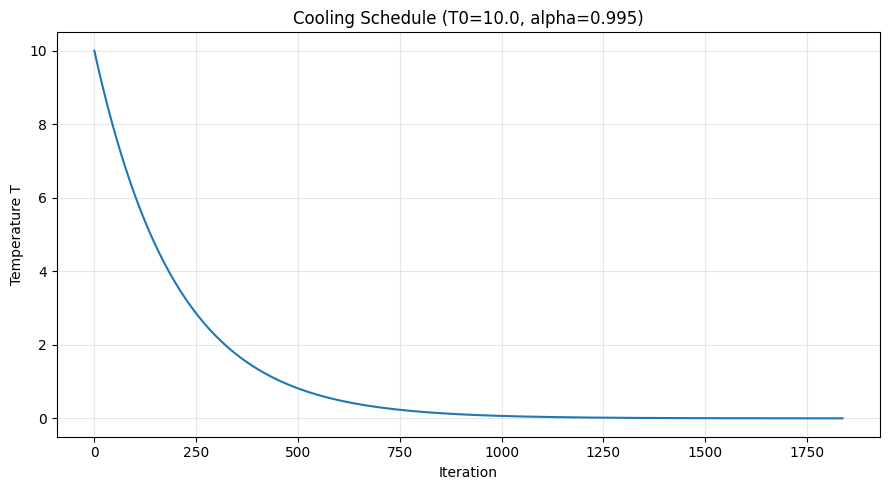

In [75]:

def plot_cooling_schedule(initial_temp, cooling_rate, min_temp=1e-3,
                          max_steps=10000):
    temperatures = []
    temperature = float(initial_temp)

    for step in range(max_steps):
        if temperature < min_temp:
            break
        temperatures.append(temperature)
        temperature *= cooling_rate

    plt.figure(figsize=(9, 5))
    plt.plot(temperatures)
    plt.xlabel("Iteration")
    plt.ylabel("Temperature T")
    plt.title(
        f"Cooling Schedule (T0={initial_temp}, alpha={cooling_rate})"
    )
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_cooling_schedule(10.0, 0.995)


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [76]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# TASK 6: ALGORITHM BEHAVIOR ANALYSIS
# So sanh 4 thuat toan tren N = 4 va N = 8
# Moi truong hop chay 100 lan voi ban co khoi tao khac nhau
# ============================================================

N_VALUES = [4, 8]
N_RUNS = 100
BASE_SEED = 20261016

# Dung cung bo tham so SA cho moi lan thi nghiem
SA_INITIAL_TEMP = 10.0
SA_COOLING_RATE = 0.995
SA_MIN_TEMP = 1e-3
SA_MAX_STEPS = 10000

# Cac thuat toan da cai dat o Task 1-3 va Task 5
algorithms = {
    "Steepest ascent HC": steepest_hill_climbing,
    "Inefficient stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient stochastic HC": efficient_stochastic_hill_climbing,
    "Simulated Annealing": simulated_annealing
}

records = []

for n in N_VALUES:
    for algorithm_name, algorithm in algorithms.items():

        print(f"Running N={n} | {algorithm_name} ...")

        for run in range(N_RUNS):

            # Seed rieng cho moi lan chay, de co the lap lai thi nghiem
            seed = BASE_SEED + n * 100000 + list(algorithms).index(
                algorithm_name
            ) * 1000 + run
            np.random.seed(seed)

            # Tao ban co khoi tao moi
            initial_board = random_board(n)

            # Do thoi gian thuc thi thuat toan
            start_time = time.perf_counter()

            if algorithm_name == "Simulated Annealing":
                board, history, evaluations = algorithm(
                    initial_board,
                    initial_temp=SA_INITIAL_TEMP,
                    cooling_rate=SA_COOLING_RATE,
                    min_temp=SA_MIN_TEMP,
                    max_steps=SA_MAX_STEPS
                )
            else:
                board, history, evaluations = algorithm(initial_board)

            runtime = time.perf_counter() - start_time

            # Danh gia trang thai cuoi cung
            final_conflicts = conflicts(board)
            success = (final_conflicts == 0)

            records.append({
                "Algorithm": algorithm_name,
                "N": n,
                "Run": run + 1,
                "Runtime (seconds)": runtime,
                "Final conflicts": final_conflicts,
                "Optimal solution": success,
                "Steps": len(history) - 1,
                "Evaluations": evaluations
            })

# Luu ket qua tung lan chay
task6_runs_df = pd.DataFrame(records)

# ============================================================
# BANG TONG HOP: GIA TRI TRUNG BINH CUA 100 LAN CHAY
# ============================================================

task6_summary = (
    task6_runs_df
    .groupby(["Algorithm", "N"], as_index=False)
    .agg(
        Runs=("Run", "count"),
        Avg_runtime=("Runtime (seconds)", "mean"),
        Avg_conflicts=("Final conflicts", "mean"),
        Successful_runs=("Optimal solution", "sum"),
        Avg_steps=("Steps", "mean"),
        Avg_evaluations=("Evaluations", "mean")
    )
)

task6_summary["Optimal solution rate (%)"] = (
    task6_summary["Successful_runs"] /
    task6_summary["Runs"] * 100
)

# Sap xep theo kich thuoc ban co va ten thuat toan
task6_summary = task6_summary[
    [
        "Algorithm",
        "N",
        "Runs",
        "Avg_runtime",
        "Avg_conflicts",
        "Optimal solution rate (%)",
        "Avg_steps",
        "Avg_evaluations"
    ]
].sort_values(["N", "Algorithm"]).reset_index(drop=True)

print("\nTASK 6 - SUMMARY (100 RUNS PER ALGORITHM AND BOARD SIZE)")
display(task6_summary.round(6))

# Bang dung de dua vao bao cao
report_table = task6_summary[
    [
        "Algorithm",
        "N",
        "Avg_runtime",
        "Avg_conflicts",
        "Optimal solution rate (%)"
    ]
].rename(columns={
    "N": "Board size",
    "Avg_runtime": "Avg. Run time (seconds)",
    "Avg_conflicts": "Avg. number of conflicts",
    "Optimal solution rate (%)": "% runs ending in optimal solution"
})

print("\nTABLE FOR THE REPORT")
display(report_table.round(6))

# Luu CSV de co the dung lai neu can
task6_runs_df.to_csv("task6_all_runs.csv", index=False)
report_table.to_csv("task6_summary.csv", index=False)

print("Da luu: task6_all_runs.csv va task6_summary.csv")


Running N=4 | Steepest ascent HC ...
Running N=4 | Inefficient stochastic HC ...
Running N=4 | Efficient stochastic HC ...
Running N=4 | Simulated Annealing ...
Running N=8 | Steepest ascent HC ...
Running N=8 | Inefficient stochastic HC ...
Running N=8 | Efficient stochastic HC ...
Running N=8 | Simulated Annealing ...

TASK 6 - SUMMARY (100 RUNS PER ALGORITHM AND BOARD SIZE)


,Algorithm,N,Runs,Avg_runtime,Avg_conflicts,Optimal solution rate (%),Avg_steps,Avg_evaluations
0,Efficient stochastic HC,4,100,0.000443,0.83,31.0,1.91,35.62
1,Inefficient stochastic HC,4,100,0.000211,0.85,30.0,1.71,30.04
2,Simulated Annealing,4,100,0.001263,0.00,100.0,108.85,109.85
3,Steepest ascent HC,4,100,0.000185,0.65,45.0,1.50,25.60
4,Efficient stochastic HC,8,100,0.003340,1.26,15.0,5.22,214.37
5,Inefficient stochastic HC,8,100,0.002961,1.34,15.0,4.88,321.88
6,Simulated Annealing,8,100,0.020548,0.19,81.0,1105.81,1106.81
7,Steepest ascent HC,8,100,0.002230,1.16,17.0,3.30,232.28



TABLE FOR THE REPORT


,Algorithm,Board size,Avg. Run time (seconds),Avg. number of conflicts,% runs ending in optimal solution
0,Efficient stochastic HC,4,0.000443,0.83,31.0
1,Inefficient stochastic HC,4,0.000211,0.85,30.0
2,Simulated Annealing,4,0.001263,0.00,100.0
3,Steepest ascent HC,4,0.000185,0.65,45.0
4,Efficient stochastic HC,8,0.003340,1.26,15.0
5,Inefficient stochastic HC,8,0.002961,1.34,15.0
6,Simulated Annealing,8,0.020548,0.19,81.0
7,Steepest ascent HC,8,0.002230,1.16,17.0


Da luu: task6_all_runs.csv va task6_summary.csv


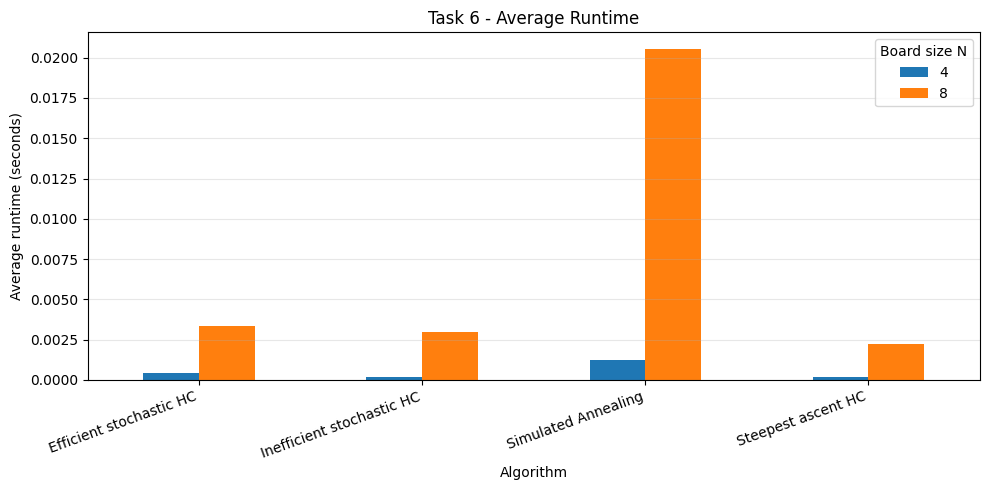

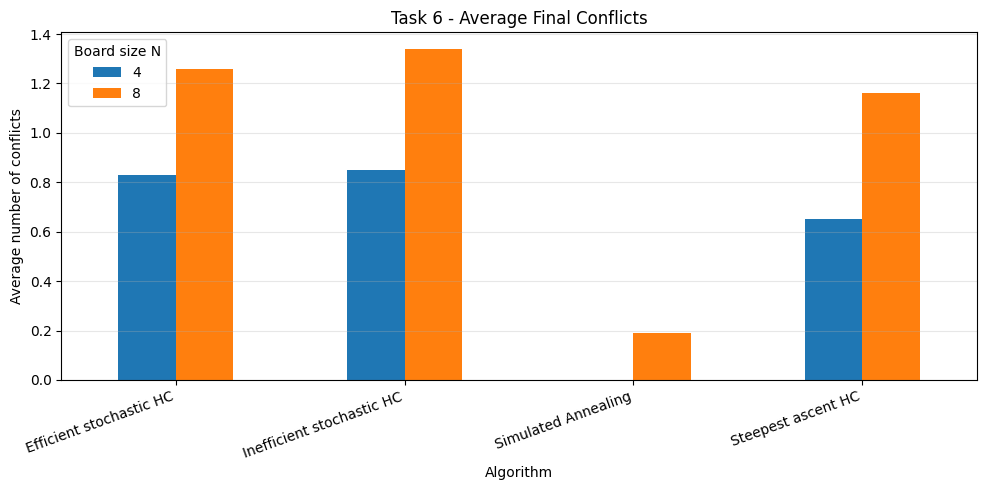

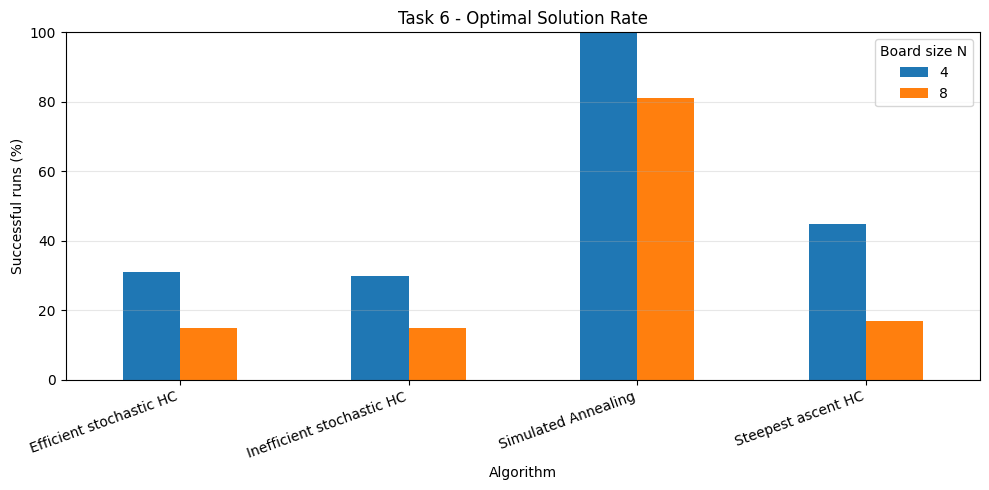

In [77]:

# ============================================================
# TASK 6: BIỂU ĐỒ SO SÁNH
# ============================================================

# 1. Thoi gian chay trung binh
runtime_pivot = task6_summary.pivot(
    index="Algorithm",
    columns="N",
    values="Avg_runtime"
)

ax = runtime_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Task 6 - Average Runtime")
ax.set_xlabel("Algorithm")
ax.set_ylabel("Average runtime (seconds)")
ax.legend(title="Board size N")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 2. So xung dot trung binh
conflict_pivot = task6_summary.pivot(
    index="Algorithm",
    columns="N",
    values="Avg_conflicts"
)

ax = conflict_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Task 6 - Average Final Conflicts")
ax.set_xlabel("Algorithm")
ax.set_ylabel("Average number of conflicts")
ax.legend(title="Board size N")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Ty le tim duoc loi giai toi uu
success_pivot = task6_summary.pivot(
    index="Algorithm",
    columns="N",
    values="Optimal solution rate (%)"
)

ax = success_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Task 6 - Optimal Solution Rate")
ax.set_xlabel("Algorithm")
ax.set_ylabel("Successful runs (%)")
ax.set_ylim(0, 100)
ax.legend(title="Board size N")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.


Algorithm: Steepest Hill Climbing
Initial board: [1 6 2 0 5 5 5 4]
Initial conflicts: 7
Best board: [np.int64(1), np.int64(6), np.int64(2), 7, np.int64(5), 3, 0, np.int64(4)]
Final conflicts: 1
Recorded history points: 4
Evaluations: 225
Runtime: 0.005521 seconds

Algorithm: Inefficient Stochastic HC
Initial board: [1 3 5 3 0 3 0 0]
Initial conflicts: 9
Best board: [4, 1, np.int64(5), 0, 6, np.int64(3), 7, 2]
Final conflicts: 0
Recorded history points: 8
Evaluations: 393
Runtime: 0.011308 seconds

Algorithm: Efficient Stochastic HC
Initial board: [2 6 3 6 3 3 3 0]
Initial conflicts: 11
Best board: [np.int64(2), np.int64(6), np.int64(3), 1, 7, 5, 0, 2]
Final conflicts: 1
Recorded history points: 9
Evaluations: 291
Runtime: 0.008034 seconds

Algorithm: Simulated Annealing
Initial board: [6 2 3 4 0 0 3 1]
Initial conflicts: 6
Best board: [5, 2, 0, 7, 3, 1, 6, 4]
Final conflicts: 0
Recorded history points: 960
Evaluations: 960
Runtime: 0.025533 seconds


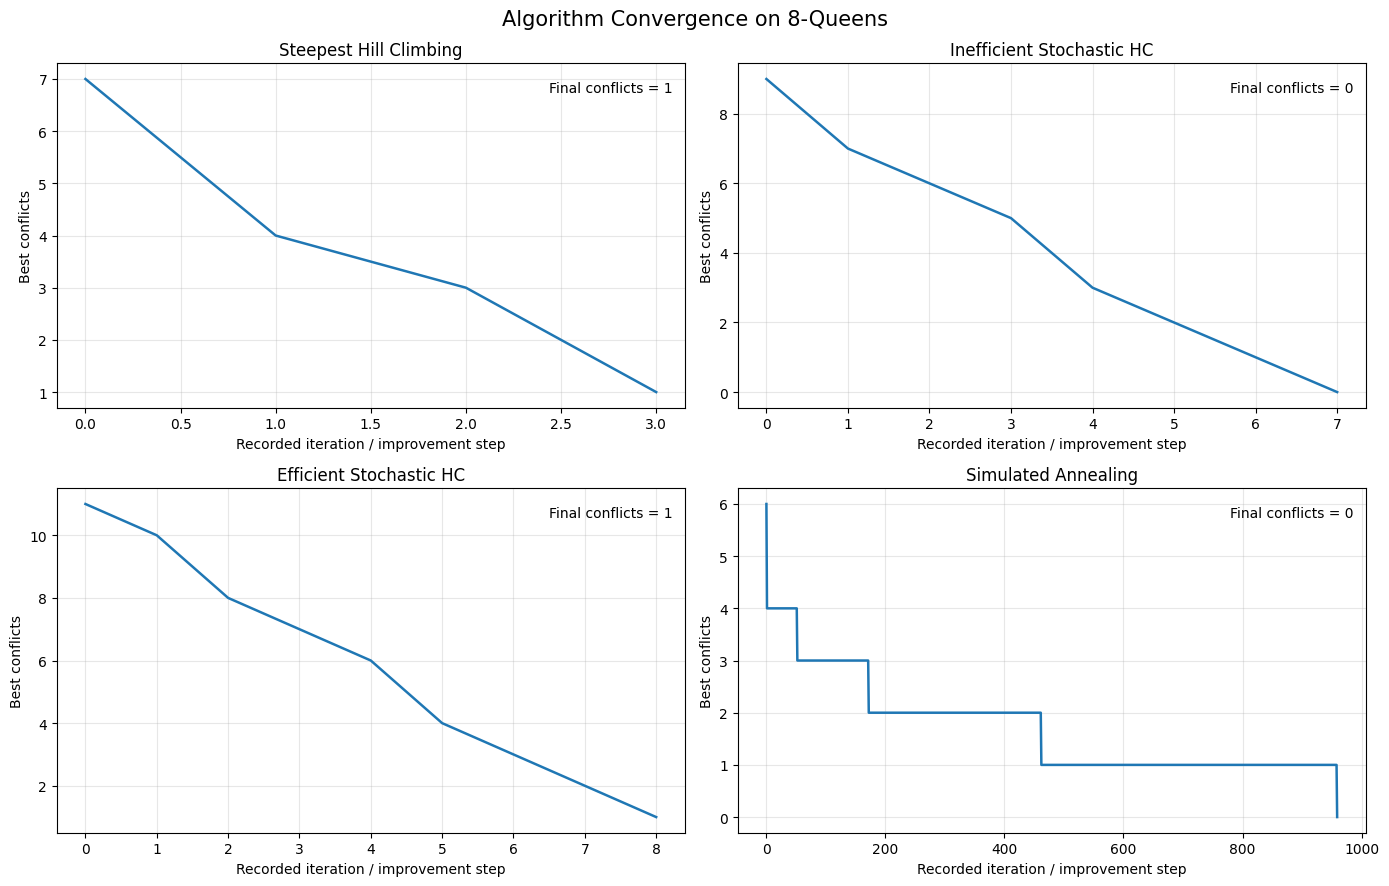

In [78]:

# ============================================================
# TASK 6: ALGORITHM CONVERGENCE - N-QUEENS
# Ve duong hoi tu cua 4 thuat toan tren bai toan 8-Queens
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

N = 8
SEED = 2026

# Danh sach cac thuat toan va tham so
algorithms = [
    ("Steepest Hill Climbing", steepest_hill_climbing),
    ("Inefficient Stochastic HC", inefficient_stochastic_hill_climbing),
    ("Efficient Stochastic HC", efficient_stochastic_hill_climbing),
    ("Simulated Annealing", simulated_annealing)
]

# Luu ket qua cua tung thuat toan
convergence_results = {}

for i, (name, algorithm) in enumerate(algorithms):
    # Dat seed rieng de ket qua co the tai lap
    np.random.seed(SEED + i)

    # Tao ban co ban dau moi
    initial_board = random_board(N)
    initial_conflicts = conflicts(initial_board)

    start_time = time.perf_counter()

    if name == "Simulated Annealing":
        best_board, history, evaluations = algorithm(
            initial_board,
            initial_temp=10.0,
            cooling_rate=0.995,
            min_temp=1e-3,
            max_steps=10000
        )
    else:
        best_board, history, evaluations = algorithm(
            initial_board,
            max_steps=10000
        )

    runtime = time.perf_counter() - start_time

    convergence_results[name] = {
        "initial_board": initial_board,
        "initial_conflicts": initial_conflicts,
        "board": best_board,
        "history": history,
        "final_conflicts": conflicts(best_board),
        "evaluations": evaluations,
        "runtime": runtime
    }

    print("\n" + "=" * 55)
    print("Algorithm:", name)
    print("Initial board:", initial_board)
    print("Initial conflicts:", initial_conflicts)
    print("Best board:", best_board)
    print("Final conflicts:", conflicts(best_board))
    print("Recorded history points:", len(history))
    print("Evaluations:", evaluations)
    print(f"Runtime: {runtime:.6f} seconds")

# ------------------------------------------------------------
# Ve 4 do thi hoi tu tren cung mot hinh
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, (name, _) in zip(axes, algorithms):
    history = convergence_results[name]["history"]

    # Moi diem trong history la mot gia tri duoc ghi nhan
    ax.plot(range(len(history)), history, linewidth=1.8)

    ax.set_title(name)
    ax.set_xlabel("Recorded iteration / improvement step")
    ax.set_ylabel("Best conflicts")
    ax.grid(True, alpha=0.3)

    final_score = convergence_results[name]["final_conflicts"]
    ax.text(
        0.98, 0.95,
        f"Final conflicts = {final_score}",
        transform=ax.transAxes,
        ha="right",
        va="top"
    )

fig.suptitle("Algorithm Convergence on 8-Queens", fontsize=15)
plt.tight_layout()
plt.show()


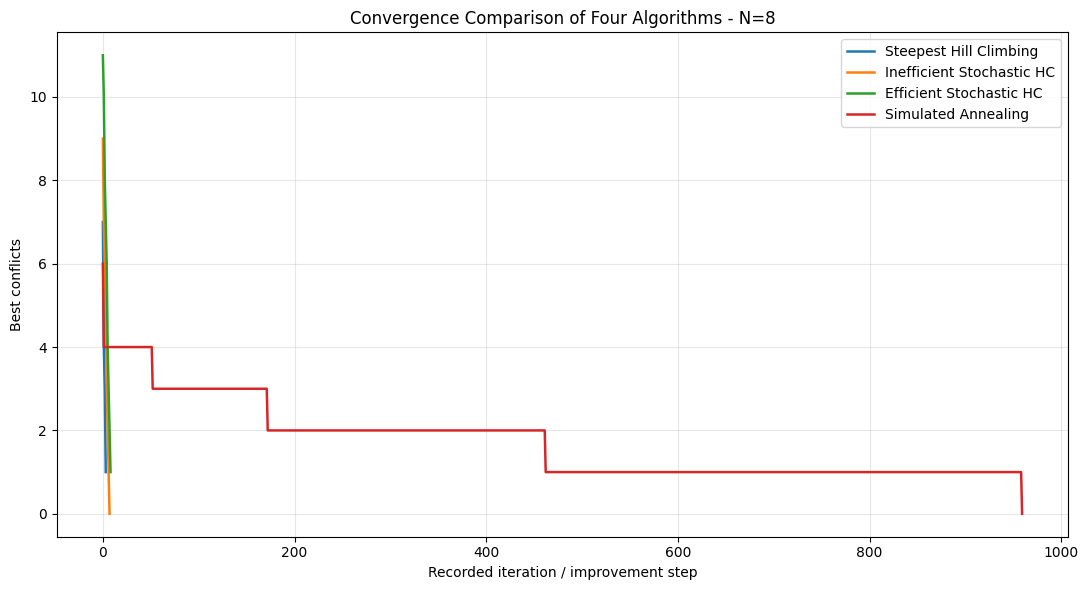

In [79]:

plt.figure(figsize=(11, 6))

for name, _ in algorithms:
    history = convergence_results[name]["history"]
    plt.plot(
        range(len(history)),
        history,
        label=name,
        linewidth=1.8
    )

plt.xlabel("Recorded iteration / improvement step")
plt.ylabel("Best conflicts")
plt.title("Convergence Comparison of Four Algorithms - N=8")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

SCALABILITY EXPERIMENT SUMMARY


,N,Algorithm,Runs,Mean_runtime,Median_runtime,Mean_conflicts,Mean_evaluations,Mean_steps,Success_rate,Success_rate (%)
0,4,Efficient Stochastic HC,20,0.000633,0.000817,0.80,28.95,1.80,0.45,45.0
1,4,Inefficient Stochastic HC,20,0.000364,0.000402,0.75,30.40,1.90,0.45,45.0
2,4,Steepest Hill Climbing,20,0.000309,0.000339,0.50,31.60,2.05,0.50,50.0
3,8,Efficient Stochastic HC,20,0.005923,0.005801,1.45,208.20,4.80,0.15,15.0
4,8,Inefficient Stochastic HC,20,0.005745,0.006063,1.40,328.60,4.95,0.10,10.0
5,8,Steepest Hill Climbing,20,0.003635,0.003618,1.45,213.80,2.95,0.15,15.0
6,12,Efficient Stochastic HC,20,0.009024,0.009288,2.05,490.20,7.25,0.10,10.0
7,12,Inefficient Stochastic HC,20,0.028604,0.029088,2.00,1228.60,8.35,0.05,5.0
8,12,Steepest Hill Climbing,20,0.018881,0.018431,1.40,727.00,4.60,0.10,10.0
9,16,Efficient Stochastic HC,20,0.023365,0.021734,2.35,1065.70,10.50,0.00,0.0


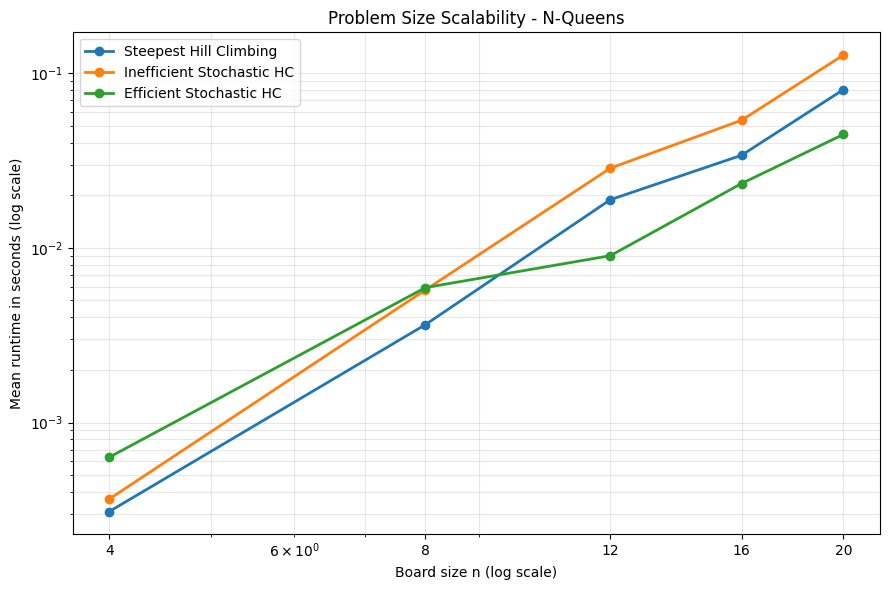

EMPIRICAL SCALING ESTIMATES


,Algorithm,Empirical exponent p,Approximate scaling,Interpretation
0,Steepest Hill Climbing,3.448,O(n^3.45),Runtime trend estimated from measured data; no...
1,Inefficient Stochastic HC,3.618,O(n^3.62),Runtime trend estimated from measured data; no...
2,Efficient Stochastic HC,2.542,O(n^2.54),Runtime trend estimated from measured data; no...


In [80]:

# ============================================================
# TASK 6: PROBLEM SIZE SCALABILITY
# Runtime scaling for N = 4, 8, 12, 16, 20
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_VALUES = [4, 8, 12, 16, 20]
N_RUNS = 20
MAX_STEPS = 10000
BASE_SEED = 62000

scalability_algorithms = {
    "Steepest Hill Climbing": steepest_hill_climbing,
    "Inefficient Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing
}

records = []

for n in N_VALUES:
    for alg_index, (alg_name, algorithm) in enumerate(
        scalability_algorithms.items()
    ):
        for run in range(N_RUNS):
            # Seed khac nhau cho moi kich thuoc, thuat toan va lan chay
            seed = BASE_SEED + n * 10000 + alg_index * 1000 + run
            np.random.seed(seed)

            initial_board = random_board(n)

            start_time = time.perf_counter()

            board, history, evaluations = algorithm(
                initial_board,
                max_steps=MAX_STEPS
            )

            runtime = time.perf_counter() - start_time
            final_conflicts = conflicts(board)

            records.append({
                "N": n,
                "Algorithm": alg_name,
                "Run": run + 1,
                "Runtime (seconds)": runtime,
                "Final conflicts": final_conflicts,
                "Evaluations": evaluations,
                "Steps": len(history) - 1,
                "Success": final_conflicts == 0
            })

scalability_df = pd.DataFrame(records)

# Tong hop ket qua theo kich thuoc va thuat toan
scalability_summary = (
    scalability_df
    .groupby(["N", "Algorithm"], as_index=False)
    .agg(
        Runs=("Run", "count"),
        Mean_runtime=("Runtime (seconds)", "mean"),
        Median_runtime=("Runtime (seconds)", "median"),
        Mean_conflicts=("Final conflicts", "mean"),
        Mean_evaluations=("Evaluations", "mean"),
        Mean_steps=("Steps", "mean"),
        Success_rate=("Success", "mean")
    )
)

scalability_summary["Success_rate (%)"] = (
    scalability_summary["Success_rate"] * 100
)

print("SCALABILITY EXPERIMENT SUMMARY")
display(scalability_summary.round(6))

# ------------------------------------------------------------
# Log-log plot: mean runtime vs board size
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for alg_name in scalability_algorithms:
    subset = scalability_summary[
        scalability_summary["Algorithm"] == alg_name
    ].sort_values("N")

    # Loai cac gia tri 0 neu co, vi truc log khong bieu dien duoc 0
    valid = subset[subset["Mean_runtime"] > 0]

    plt.loglog(
        valid["N"],
        valid["Mean_runtime"],
        marker="o",
        linewidth=2,
        label=alg_name
    )

plt.xlabel("Board size n (log scale)")
plt.ylabel("Mean runtime in seconds (log scale)")
plt.title("Problem Size Scalability - N-Queens")
plt.xticks(N_VALUES, [str(n) for n in N_VALUES])
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Estimate empirical exponent:
# runtime approximately proportional to n^p
# log(runtime) = p * log(n) + constant
# ------------------------------------------------------------

exponent_records = []

for alg_name in scalability_algorithms:
    subset = scalability_summary[
        scalability_summary["Algorithm"] == alg_name
    ].sort_values("N")

    valid = subset[
        (subset["Mean_runtime"] > 0) &
        np.isfinite(subset["Mean_runtime"])
    ]

    slope, intercept = np.polyfit(
        np.log(valid["N"]),
        np.log(valid["Mean_runtime"]),
        1
    )

    exponent_records.append({
        "Algorithm": alg_name,
        "Empirical exponent p": slope,
        "Approximate scaling": f"O(n^{slope:.2f})",
        "Interpretation": (
            "Runtime trend estimated from measured data; "
            "not a formal worst-case bound."
        )
    })

exponent_df = pd.DataFrame(exponent_records)

print("EMPIRICAL SCALING ESTIMATES")
display(exponent_df.round(3))


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [81]:
# ---------- Advanced: các toán tử di chuyển khác ----------
# Mỗi toán tử nhận board (list) và trả về board mới (không sửa board cũ).
import math, random, time
import pandas as pd

def seed_all(s):
    """Đặt seed cho cả random và numpy để chạy lại ra đúng kết quả."""
    random.seed(s); np.random.seed(s)

def move_single_step(board):
    """Dời 1 quân lên/xuống đúng 1 ô (nếu không ra khỏi bàn cờ)."""
    n = len(board); b = list(board)
    while True:
        c = random.randrange(n); r = b[c] + random.choice((-1, 1))
        if 0 <= r < n: b[c] = r; return b

def move_column_swap(board):
    """Đổi hàng của 2 quân ở 2 cột ngẫu nhiên."""
    n = len(board); b = list(board)
    i, j = random.sample(range(n), 2); b[i], b[j] = b[j], b[i]; return b

def move_dual_queen(board):
    """Chọn 2 quân, dời cả hai cùng lúc sang hàng mới ngẫu nhiên."""
    n = len(board); b = list(board)
    for c in random.sample(range(n), 2):
        r = random.randrange(n - 1)
        b[c] = r + 1 if r >= b[c] else r
    return b

def queen_conflicts(board):
    """Số quân khác đang tấn công từng quân (dùng đếm theo hàng/đường chéo, O(n))."""
    n = len(board); h = [0]*n; d1 = [0]*(2*n); d2 = [0]*(2*n)
    for i, r in enumerate(board):
        h[r] += 1; d1[i + r] += 1; d2[i - r + n] += 1
    return [h[r] - 1 + d1[i + r] - 1 + d2[i - r + n] - 1 for i, r in enumerate(board)]

def move_adaptive(board, p_focus=0.7):
    """Adaptive: với xác suất 0.7 chọn quân theo trọng số số xung đột của nó (quân xung đột nhiều thì dễ được chọn)
    rồi dời sang hàng ngẫu nhiên; ngược lại chọn ngẫu nhiên 1 trong 3 toán tử còn lại."""
    n = len(board)
    qc = queen_conflicts(board)
    if random.random() < p_focus and sum(qc) > 0:
        c = random.choices(range(n), weights=qc)[0]
        b = list(board); r = random.randrange(n - 1); b[c] = r + 1 if r >= b[c] else r
        return b
    return random.choice((move_single_step, move_column_swap, move_dual_queen))(board)

def move_standard(board):
    """Toán tử gốc: dời 1 quân sang hàng khác trong cùng cột."""
    n = len(board); b = list(board); c = random.randrange(n); r = random.randrange(n - 1)
    b[c] = r + 1 if r >= b[c] else r; return b

PERM_INIT = {"column swap (khởi tạo hoán vị)"}   # swap giữ nguyên tập hàng nên cần bắt đầu từ hoán vị
OPERATORS = {"standard (1 quân, hàng bất kỳ)": move_standard, "single-step (±1 ô)": move_single_step,
             "column swap":  move_column_swap, "column swap (khởi tạo hoán vị)": move_column_swap, "dual-queen": move_dual_queen, "adaptive": move_adaptive}

def stochastic_hc_op(board, op, max_iter=3000):
    """Efficient stochastic HC với toán tử `op`: sinh 1 láng giềng, nhận nếu f giảm ngặt. Ngân sách cố định max_iter lần thử."""
    board = list(board); f = conflicts(board); hist = [f]
    for it in range(1, max_iter + 1):
        if f == 0: break
        nb_ = op(board); fn = conflicts(nb_)
        if fn < f: board, f = nb_, fn
        hist.append(f)
    return dict(board=board, f=f, iters=len(hist) - 1, hist=hist)

ADV_RUNS, ADV_ITER = 100, 3000
adv = {}
for n in (8, 12):
    for name, op in OPERATORS.items():
        seed_all(500 + n)
        finals, times, iters_ok, curves = [], [], [], []
        for _ in range(ADV_RUNS):
            b = np.random.permutation(n) if name in PERM_INIT else random_board(n); t0 = time.perf_counter()
            r = stochastic_hc_op(b, op, ADV_ITER); dt = (time.perf_counter() - t0) * 1e3
            finals.append(r["f"])
            if r["f"] == 0: times.append(dt); iters_ok.append(r["iters"])
            curves.append(r["hist"] + [r["hist"][-1]] * (ADV_ITER + 1 - len(r["hist"])))   # đệm bằng giá trị cuối
        adv[(n, name)] = dict(finals=np.array(finals), curve=np.mean(curves, axis=0),
                              ms_ok=np.mean(times) if times else np.nan, it_ok=np.mean(iters_ok) if iters_ok else np.nan)

adv_table = pd.DataFrame([{"n": n, "operator": name, "% optimal": (v["finals"] == 0).mean() * 100,
                           "avg final f": v["finals"].mean(), "avg time to solution (ms)": v["ms_ok"],
                           "avg iterations to solution": v["it_ok"]} for (n, name), v in adv.items()])
adv_table.round(2)

,n,operator,% optimal,avg final f,avg time to solution (ms),avg iterations to solution
0,8,"standard (1 quân, hàng bất kỳ)",10.0,1.31,1.30,101.50
1,8,single-step (±1 ô),0.0,3.40,NaN,NaN
2,8,column swap,0.0,4.41,NaN,NaN
3,8,column swap (khởi tạo hoán vị),32.0,0.80,0.45,31.94
4,8,dual-queen,22.0,0.79,20.72,1091.09
5,8,adaptive,26.0,0.95,16.64,636.73
6,12,"standard (1 quân, hàng bất kỳ)",6.0,1.72,3.08,223.17
7,12,single-step (±1 ô),0.0,5.41,NaN,NaN
8,12,column swap,0.0,6.40,NaN,NaN
9,12,column swap (khởi tạo hoán vị),22.0,0.98,2.41,142.64


### Nhận xét và phân tích

- **Single-step:** Không tìm được lời giải ở cả \(n=8\) và \(n=12\). Do mỗi lần chỉ di chuyển quân hậu lên hoặc xuống một ô, thuật toán bị giới hạn trong việc thay đổi trạng thái bàn cờ. Khi không còn bước đi nào giúp giảm số xung đột, thuật toán dễ mắc kẹt tại cực tiểu cục bộ.

- **Column swap:** Tỷ lệ tìm được lời giải đạt 0% ở cả hai kích thước. Toán tử này chỉ hoán đổi hàng của hai quân hậu nên số quân hậu trên mỗi hàng không thay đổi. Vì vậy, nếu bàn cờ ban đầu có nhiều quân hậu cùng hàng, các xung đột này vẫn tồn tại và khiến thuật toán khó tìm được lời giải.

- **Column swap kết hợp khởi tạo hoán vị:** Đây là cấu hình có kết quả tốt nhất, với tỷ lệ tìm được lời giải đạt 32% ở \(n=8\) và 22% ở \(n=12\). Cách khởi tạo này đảm bảo mỗi hàng và mỗi cột chỉ có một quân hậu, giúp loại bỏ xung đột cùng hàng ngay từ đầu. Nhờ đó, thuật toán chỉ cần tập trung xử lý xung đột đường chéo, giúp quá trình tìm kiếm hiệu quả hơn.

- **Dual-queen:** Di chuyển đồng thời hai quân hậu giúp thuật toán thay đổi trạng thái linh hoạt hơn và có thêm cơ hội giảm xung đột trong mỗi bước. Tuy nhiên, số trạng thái lân cận tăng theo kích thước bàn cờ, làm tăng chi phí tìm kiếm. Vì vậy, tỷ lệ tìm được lời giải giảm từ 22% ở \(n=8\) xuống còn 3% ở \(n=12\).

- **Adaptive:** Tỷ lệ tìm được lời giải đạt 26% ở \(n=8\) và 10% ở \(n=12\). Việc ưu tiên những quân hậu có nhiều xung đột giúp thuật toán tập trung xử lý các vị trí cần cải thiện. Tuy nhiên, thuật toán phải đánh giá mức độ xung đột và lựa chọn toán tử phù hợp, khiến thời gian tính toán tăng lên.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem